# EDA básico e inspección de calidad de ESCO

El primer paso es importar las librerias que se van a utilizar.

In [2]:
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
import matplotlib.pyplot as plt
from pathlib import Path

## Carga de datos
Se empieza comprobando que se identifican bien los datos para poder cargarlos. De momento se trabaja con tres archivos .csv: 
- occupations_es.csv, que incluye una lista de ocupaciones.
- skills_es.csv, que incluye una lista de habilidades.
- occupationSkillRelation_es.csv, que relaciona habilidades con ocupaciones.

In [3]:
ruta_datos = Path("../data/raw/esco") # Definir la ruta de los archivos

print("¿Existe la carpeta?:", ruta_datos.exists())
print("Archivos encontrados:", list(ruta_datos.glob("*.csv")))

¿Existe la carpeta?: True
Archivos encontrados: [WindowsPath('../data/raw/esco/occupationSkillRelations_es.csv'), WindowsPath('../data/raw/esco/occupations_es.csv'), WindowsPath('../data/raw/esco/skills_es.csv')]


Viendo que no hay problemas, se suben los archivos.

In [4]:
occupations = pd.read_csv(ruta_datos / "occupations_es.csv", encoding="utf-8")
skills = pd.read_csv(ruta_datos / "skills_es.csv", encoding="utf-8")
occupation_skill_relations = pd.read_csv(ruta_datos / "occupationSkillRelations_es.csv", encoding="utf-8")

print("Los tres archivos se han cargado correctamente.")

Los tres archivos se han cargado correctamente.


Se guardan en un diccionario para acceder a ellos comodamente.

In [5]:
datasets = {
    "occupations": occupations,
    "skills": skills,
    "occupation_skill_relations": occupation_skill_relations
}

## Estudio de la muestra

### Tamaño de la muestra

Luego se comprueban las dimensiones de estos archivos. En el código saldrá (nº de registros, nº de columnas).

In [6]:
for nombre, df in datasets.items():
    print(f"{nombre} tiene {df.shape[1]} columnas y {df.shape[0]} registros.")

occupations tiene 15 columnas y 3043 registros.
skills tiene 13 columnas y 13960 registros.
occupation_skill_relations tiene 6 columnas y 126051 registros.


Se miran los primeros registros para ver que se esté leyendo correctamente el archivo.

In [7]:
with pd.option_context("display.max_colwidth", 50):
    display(occupations.head(1))
    display(skills.head(1))
    display(occupation_skill_relations.head(1))

,conceptType,conceptUri,iscoGroup,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,regulatedProfessionNote,scopeNote,definition,inScheme,description,code,naceCode
0,Occupation,http://data.europa.eu/esco/occupation/00030d09...,2654,director técnico/directora técnica,directora técnica\ndirector técnico,NaN,released,2024-01-25T11:28:50.295Z,http://data.europa.eu/esco/regulated-professio...,NaN,NaN,http://data.europa.eu/esco/concept-scheme/memb...,Los directores técnicos elaboran las visiones ...,2654.1.7,http://data.europa.eu/ux2/nace2.1/9031


,conceptType,conceptUri,skillType,reuseLevel,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,scopeNote,definition,inScheme,description
0,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/0005c151-5b5a...,skill/competence,sector-specific,gestionar tareas en relación con los músicos,NaN,NaN,released,2023-11-30T15:53:37.136Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Asignar y gestionar las tareas del personal en...


,occupationUri,occupationLabel,relationType,skillType,skillUri,skillLabel
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,knowledge,http://data.europa.eu/esco/skill/fed5b267-73fa...,theatre techniques


### Tipo de datos

Se analiza el tipo de dato de cada columna de cada archivo, para ver si se detectan inconsistencias.

In [8]:
for nombre, df in datasets.items():
    print(f"\nDataset: {nombre}")
    print(f"{'-' * 50}")
    print("\nTipos de datos por columna:")
    df.info()


Dataset: occupations
--------------------------------------------------

Tipos de datos por columna:
<class 'pandas.DataFrame'>
RangeIndex: 3043 entries, 0 to 3042
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   conceptType              3043 non-null   str    
 1   conceptUri               3043 non-null   str    
 2   iscoGroup                3043 non-null   int64  
 3   preferredLabel           3043 non-null   str    
 4   altLabels                2902 non-null   str    
 5   hiddenLabels             2 non-null      str    
 6   status                   3043 non-null   str    
 7   modifiedDate             3043 non-null   str    
 8   regulatedProfessionNote  3043 non-null   str    
 9   scopeNote                0 non-null      float64
 10  definition               0 non-null      float64
 11  inScheme                 3043 non-null   str    
 12  description              3043 non-null   

En occupations se observa que la mayoria de entradas son de texto, salvo iscoGroup, que al ser un código numérico es un entero. scopeNote y definition salen como float, pero también se ve que son todas entradas vacías. Por tanto, no son realmnete números, sino que no contienen nada. Por otra parte, se espera que modifiedData sea una fecha, pero se reconoce como texto; más adelante se verá si conviene cambiarlo. Se puede decir lo mismo de skills. No se ve nada destacable en occupation_skill_relation.

### Variables principales


#### Ocupaciones

Empezando por occupations, la primera columa es conceptType.

In [9]:
print(f"Número de valores distintos: {occupations["conceptType"].nunique()}")
print(occupations["conceptType"].unique())

Número de valores distintos: 1
<StringArray>
['Occupation']
Length: 1, dtype: str


Esta columna tan solo muestra un mismo valor en todos los registros. En el conjunto de datos de ESCO, sirve para indicar qué tipo de concepto ESCO representa cada registro. Que en el archivo occupations todos los registros tengan el valor Occupation implica que todos representan conceptos de tipo ocupación. En este archivo no aporta información, su relevancia se ve al juntar los distintos archivos.

La siguiente columna, conceptUri, es un identificador de cada puesto de trabajo, que se repite en otros archivos, como el de occupation_skill_relation para señalar ese puesto en específico, sin tener que depender de nombres que pueden cambiar.

iscoGroup es el código que indica a qué grupo de la clasificación internacional de ocupaciones ISCO (International Standard Classification of Occupations) pertenece una ocupación. Se utiliza esta clasificación para organizar las ocupaciones en grupos jerárquicos. Esto permite relacionar las ocupaciones europeas con una estructura internacional común.

Es importante destacar que se identifica como una variable numérica por ser un número entero, pero sus valores realmente son códigos de categorías, no cantidades. Con esto en mente, se estudian sus frecuencias.

In [10]:
print(f"La columna iscoGroup tiene {occupations["iscoGroup"].nunique()} valores distintos de {occupations.shape[0]} registros.")

La columna iscoGroup tiene 426 valores distintos de 3043 registros.


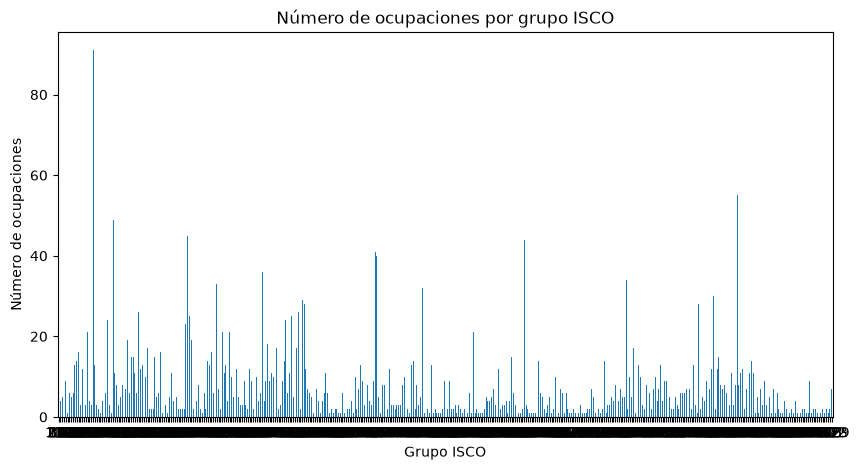

In [11]:
# Calcular la frecuencia de cada grupo ISCO
frecuencias_isco = occupations["iscoGroup"].value_counts().sort_index()

# Crear el gráfico de barras
plt.figure(figsize=(10, 5))
frecuencias_isco.plot(kind="bar")

# Añadir títulos y etiquetas
plt.title("Número de ocupaciones por grupo ISCO")
plt.xlabel("Grupo ISCO")
plt.ylabel("Número de ocupaciones")
plt.xticks(rotation=0)

# Mostrar el gráfico
plt.show()

En el gráfico de barras se observa que la distribución no es uniforme.

La columna preferredLabel tan solo indica la denominación por convención del puesto, altLabels son denominaciones alternativas, que no todos los puestos tienen ya que se ve que la columna tiene valores nulos (2902 non-null de 3043 registros), y hiddenLabels son también otras denominaciones, pero que solo aparece en dos registros.

In [12]:
print(f"Número de valores distintos en hiddenLabels: {occupations["hiddenLabels"].nunique()}")

# Obtener preferredLabel, altLabel y hiddenLabel de los dos registros con hiddenLabel no vacio
registros = occupations.loc[
    occupations["hiddenLabels"].notna(),
    ["preferredLabel", "altLabels", "hiddenLabels"]
]

print("-" * 110)
for indice, fila in registros.iterrows():
    print(f"\nRegistro {indice}")
    print(f"preferredLabel: {fila['preferredLabel']}")
    print(f"altLabels: {fila['altLabels']}")
    print(f"hiddenLabels: {fila['hiddenLabels']}")
    print("-" * 110)

Número de valores distintos en hiddenLabels: 2
--------------------------------------------------------------------------------------------------------------

Registro 189
preferredLabel: operador de grúa torre/operadora de grúa torre
altLabels: operadora de grúa torre
operador de grúa torre
operario de grúa torre
operaria de grúa torre
hiddenLabels: operador de grúa de torre
--------------------------------------------------------------------------------------------------------------

Registro 278
preferredLabel: operador de máquinas para fabricar plaguicidas/operadora de máquinas para fabricar plaguicidas
altLabels: operador de máquinas para fabricar insecticidas
operadora de máquinas para fabricar fungicidas
operadora de máquinas para fabricar plaguicidas
operadora de máquinas para fabricar insecticidas
operador de máquinas para fabricar plaguicidas
operador de máquinas para fabricar fungicidas
hiddenLabels: operador de máquinas para fabricar pesticidas
operadora de máquinas para fa

Se observa que hiddenLabels tan solo contiene mas denominaciones alternativas, por lo que se decide que en la limpiza se fusionará con altLabels, ya que no aporta nada nuevo o distinto.

In [13]:
print(f"Número de valores distintos en status: {occupations["status"].nunique()}")
print(occupations["status"].value_counts())
print("-" * 80)

print(f"Número de valores distintos en modifiedDate: {occupations["modifiedDate"].nunique()}")
print(f"Formato de las fechas en modifiedData: {occupations["modifiedDate"].iloc[0]} (ISO 8601)")
print("-" * 80)

print(f"Número de valores distintos en regulatedProfessionNote: {occupations["regulatedProfessionNote"].nunique()}")
print(occupations["regulatedProfessionNote"].value_counts())

print("Ocupaciones consideradas como reguladas:")
display(
    occupations.loc[
        occupations["regulatedProfessionNote"].str.endswith("/regulated"),
        ["preferredLabel", "regulatedProfessionNote"]
    ]
)



Número de valores distintos en status: 1
status
released    3043
Name: count, dtype: int64
--------------------------------------------------------------------------------
Número de valores distintos en modifiedDate: 2902
Formato de las fechas en modifiedData: 2024-01-25T11:28:50.295Z (ISO 8601)
--------------------------------------------------------------------------------
Número de valores distintos en regulatedProfessionNote: 2
regulatedProfessionNote
http://data.europa.eu/esco/regulated-professions/unregulated    3027
http://data.europa.eu/esco/regulated-professions/regulated        16
Name: count, dtype: int64
Ocupaciones consideradas como reguladas:


,preferredLabel,regulatedProfessionNote
39,operador de máquina recubridora de metales/operadora de máquina recubridora de metales,http://data.europa.eu/esco/regulated-professions/regulated
115,veterinario especializado/veterinaria especializada,http://data.europa.eu/esco/regulated-professions/regulated
688,enfermero de práctica avanzada/enfermera de práctica avanzada,http://data.europa.eu/esco/regulated-professions/regulated
956,veterinario oficial/veterinaria oficial,http://data.europa.eu/esco/regulated-professions/regulated
1042,farmacéutico industrial/farmacéutica industrial,http://data.europa.eu/esco/regulated-professions/regulated
1193,farmacéutico de hospital/farmacéutica de hospital,http://data.europa.eu/esco/regulated-professions/regulated
1408,médico generalista/médica generalista,http://data.europa.eu/esco/regulated-professions/regulated
1542,farmacéutico/farmacéutica,http://data.europa.eu/esco/regulated-professions/regulated
1744,arquitecto/arquitecta,http://data.europa.eu/esco/regulated-professions/regulated
1756,enfermero responsable de cuidados generales/enfermera responsable de cuidados generales,http://data.europa.eu/esco/regulated-professions/regulated


status es una columna que tan solo indica el estado "released", mientras que modifiedDate indica la fecha de modificación del registro. Está escrita como aaaa-mm-dd T horas:minutos:segudos.milisegundos en zona horaria UTC, aunque ahora mismo se identifica como texto. En la limpieza se cambiará el tipo de dato.

La columna regulatedProfessionNote contiene dos categorías: regulated y unregulated, donde una profesión regulada se entiende por aquella cuyo acceso o ejercicio está sujeto legalmente a determinados requisitos de cualificación o acreditación. Hay 16 ocupaciones reguladas y 3.027 no reguladas.

scopeNote y definition son columnas vacías.

In [14]:
print(f"Número de valores distintos en inScheme: {occupations["inScheme"].nunique()}")
print(occupations["inScheme"].value_counts())

Número de valores distintos en inScheme: 2
inScheme
http://data.europa.eu/esco/concept-scheme/member-occupations,\nhttp://data.europa.eu/esco/concept-scheme/occupations                                                                                     2921
http://data.europa.eu/esco/concept-scheme/member-occupations,\nhttp://data.europa.eu/esco/concept-scheme/8ae4b9f3-507e-4057-a145-2f96f0132613,\nhttp://data.europa.eu/esco/concept-scheme/occupations     122
Name: count, dtype: int64


La columna inScheme indica a qué esquema o conjunto de conceptos de ESCO pertenece cada ocupación. Es decir, identifica las clasificaciones o colecciones en las que está incluida. Al ver los dos posibles valores de la columna, se identifica que todas las ocupaciones pertenecen a dos esquemas comunes (esquema general de ocupaciones de ESCO y esquema de ocupaciones de los miembros de ESCO), y hay 122 ocupaciones que, además, están asociadas a un esquema adicional. Es una variable categórica que contiene listas de URI.

description es una columna que contiene una pequeña descripción de cada ocupación.

In [15]:
print(f"Número de valores distintos en naceCode: {occupations["naceCode"].nunique()}")

Número de valores distintos en naceCode: 1121


La columna naceCode presenta el código que identifica la actividad económica relacionada con una ocupación, según la clasificación NACE, que en español se conoce como Nomenclatura estadística de actividades económicas de la Comunidad Europea. Es una clasificación utilizada por la Unión Europea para organizar las actividades económicas en sectores.

#### Habilidades

En habilidades tenemos la columna concepType, conceptUri, preferedLabel, altLabels, hiddenLabels, status, modifiedDate, scopeNote, definition, inScheme y description son equivalentes a sus contrapartes en occupations y se llega a las mismas conclusiones. Se pasa a mirar las columnas que son distintas. Es decir, se miran skillType y reuseLevel.

Número de valores distintos en skillType: 2
---------------------------------------------
skillType
skill/competence    10734
knowledge            3221
Name: count, dtype: int64
---------------------------------------------
Frecuencias relativas de skillType (%):


skillType
skill/competence    76.92
knowledge           23.08
Name: proportion, dtype: float64

---------------------------------------------
---------------------------------------------
Número de valores distintos en reuseLevel: 4
---------------------------------------------
reuseLevel
sector-specific        6667
cross-sector           3788
occupation-specific    3047
transversal             453
Name: count, dtype: int64


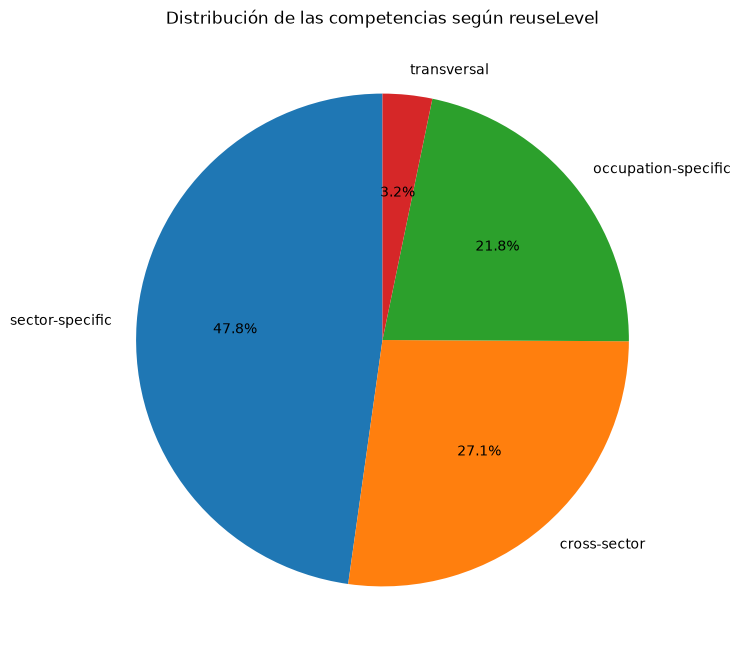

In [16]:
print(f"Número de valores distintos en skillType: {skills["skillType"].nunique()}")
print("-" * 45)
print(skills["skillType"].value_counts())
print("-" * 45)

# Calcular frecuencias relativas de skillType
frecuencias_skillType = (
    skills["skillType"].value_counts(normalize=True) * 100
)
print("Frecuencias relativas de skillType (%):")
display(frecuencias_skillType.round(2))

print("-" * 45)
print("-" * 45)

print(f"Número de valores distintos en reuseLevel: {skills["reuseLevel"].nunique()}")
print("-" * 45)
print(skills["reuseLevel"].value_counts())

# Calcular frecuencias de reuseLevel
frecuencias_reuseLevel = skills["reuseLevel"].value_counts()

# Crear gráfico de sectores
plt.figure(figsize=(8, 8))

plt.pie(
    frecuencias_reuseLevel,
    labels=frecuencias_reuseLevel.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de las competencias según reuseLevel")
plt.show()

Se observa que en skillType se distinguen habilidades aprendidas (knowledge) de adquiridas (skill/competence), teniendo más cantidad de las segundas. reuseLevel distingue habilidades que se pueden reutilizar, y por ello distingue por sector (sector-specific), por ocupación (occupation-specific), que valen en varios sectores (cross-sector) y transversales.

#### Relaciones entre ocupaciones y habilidades

En occupation_skill_relation, occupationUri se corresponde con el conceptUri de occupations y skillUri con el conceptUri de skills. occupationLAbel es la preferredLabel de occupations y skillLabel es la preferredLabel de skills, y skillType es la misma que en skills con el mismo nombre. Falta por ver relationType.

Número de valores distintos en relationType: 2
---------------------------------------------
relationType
essential    67600
optional     58451
Name: count, dtype: int64


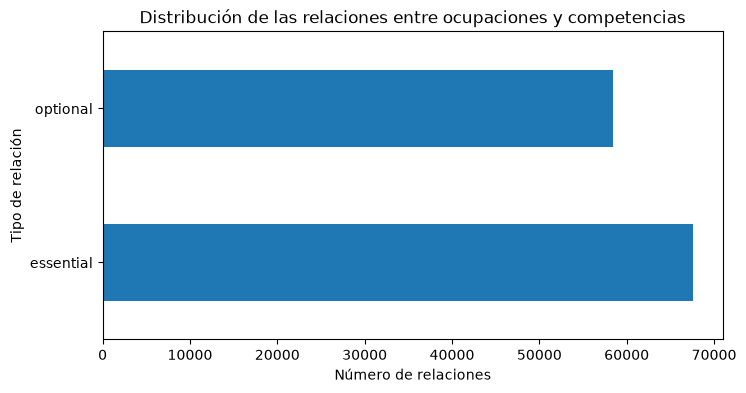

In [17]:
print(f"Número de valores distintos en relationType: {occupation_skill_relations["relationType"].nunique()}")
print("-" * 45)
print(occupation_skill_relations["relationType"].value_counts())

# Calcular frecuencias de relationType
frecuencias_relationType = occupation_skill_relations["relationType"].value_counts()

# Crear gráfico de barras horizontales
plt.figure(figsize=(8, 4))

frecuencias_relationType.plot(kind="barh")

plt.title("Distribución de las relaciones entre ocupaciones y competencias")
plt.xlabel("Número de relaciones")
plt.ylabel("Tipo de relación")

plt.show()

Se ve que distingue entre relación esencial y opcional, con el que se puede distinguir la importancia de ciertas habilidades para ciertas ocupaciones.


## Detección de posibles problemas

### Valores ausentes

Se buscan valores ausentes en la muestra.

In [18]:
for nombre, df in datasets.items():

    print(f"\n{nombre}")
    print(f"{'-' * 50}")

    vacios = df.isna().sum()

    resultado = pd.DataFrame({
        "valores_vacios": vacios,
        "porcentaje_vacios": (vacios / len(df) * 100).round(2)
    })

    print(resultado[resultado["valores_vacios"] > 0])


occupations
--------------------------------------------------
              valores_vacios  porcentaje_vacios
altLabels                141               4.63
hiddenLabels            3041              99.93
scopeNote               3043             100.00
definition              3043             100.00

skills
--------------------------------------------------
              valores_vacios  porcentaje_vacios
skillType                  5               0.04
reuseLevel                 5               0.04
altLabels               5461              39.12
hiddenLabels           13930              99.79
scopeNote              13960             100.00
definition             13960             100.00

occupation_skill_relations
--------------------------------------------------
           valores_vacios  porcentaje_vacios
skillType              59               0.05


Se observa que las columnas scopeNote y definition están completamente vacías en los dos catálogos que aparecen. No aportan información en esta versión del conjunto de datos descargado. altLabels y hiddenLabels también tienen algunos valores vacíos, pero es esperable porque no todas las profesiones tienen que tener más de una denominación. Habría que ver los valores vacíos de skillType y reuseLevel.

In [19]:
skills_vacias = skills[skills["skillType"].isna()]

display(skills_vacias.drop(columns=[
    "conceptUri",
    "conceptType",
    "status",
    "scopeNote",
    "definition",
    "inScheme"
])
)

,skillType,reuseLevel,preferredLabel,altLabels,hiddenLabels,modifiedDate,description
3627,NaN,NaN,seguridad de las tecnologías de la información y de las comunicaciones,seguridad de las TIC\nseguridad informática,NaN,2025-02-27T12:45:08.961Z,"Protección personal, protección de datos, protección de la identidad digital, medidas de seguridad, uso seguro y sostenible."
4797,NaN,NaN,comunicación y colaboración digitales,NaN,NaN,2025-02-27T12:45:08.961Z,"La comunicación en entornos digitales, el intercambio de recursos a través de herramientas en línea, el enlace con otras personas y la colaboración a través de herramientas digitales, la interactuación con las comunidades y redes y la participación en las mismas, así como la sensibilización intercultural."
5430,NaN,NaN,tratamiento digital de los datos,procesamiento digital de datos\nproceso digital de datos,NaN,2025-02-27T12:45:08.961Z,"Identificar, localizar, recuperar, almacenar, organizar y analizar información digital, evaluando su pertinencia y su propósito."
6962,NaN,NaN,resolución de problemas con herramientas digitales,resolución de problemas mediante hardware y herramientas de las TIC\nresolución de problemas mediante hardware y herramientas informáticas,NaN,2025-02-27T12:45:08.961Z,"Identificar las necesidades y los recursos digitales, tomar decisiones informadas sobre las herramientas digitales más adecuadas en función de su finalidad o necesidad, resolver los problemas conceptuales a través de medios digitales, utilizar de forma creativa tecnologías, resolver problemas técnicos, actualizar la competencia propia y de otros."
13346,NaN,NaN,creación de contenidos digitales,creación de contenidos con programas de tecnologías de la información y de las comunicaciones\ncreación de contenidos con programas informáticos\ncreación de contenidos con programas de TIC,NaN,2025-02-27T12:45:08.961Z,"Crear y editar contenido nuevo (desde procesamiento de texto hasta imágenes y video); integrar y reelaborar conocimientos y contenidos previos; producir expresiones creativas, salidas de medios y programación; tratar y aplicar derechos de propiedad intelectual y licencias."


Se identifican los valores vacíos de skillType y reuseLevel como los mismo cinco registros. Los cinco corresponden aparentemente a las áreas principales del marco DigComp (competencias digitales), integradas en la clasificación ESCO. Se estudia si esta falta de información es intencionada.

Primero se comprueba con cuantas ocupaciones se relacionan estas habilidades dentro de occupationSkillRelation.

In [20]:
areas_digcomp = skills[skills["skillType"].isna() & skills["reuseLevel"].isna()]

uri_digcomp = areas_digcomp["conceptUri"]

relaciones_digcomp = occupation_skill_relations[occupation_skill_relations["skillUri"].isin(uri_digcomp)]

conteo_relaciones = (
    relaciones_digcomp.groupby("skillUri")
    .size()
    .reset_index(name="numero_relaciones")
)

resultado = areas_digcomp.merge(
    conteo_relaciones,
    left_on="conceptUri",
    right_on="skillUri",
    how="left"
)

display(resultado[["preferredLabel", "numero_relaciones"]])

,preferredLabel,numero_relaciones
0,seguridad de las tecnologías de la información y de las comunicaciones,8
1,comunicación y colaboración digitales,15
2,tratamiento digital de los datos,20
3,resolución de problemas con herramientas digitales,6
4,creación de contenidos digitales,10


Se observa que sí que tienen relaciones con ocupaciones, por lo que no es prudente eliminar estos registros.

In [21]:
display(
    areas_digcomp[
        ["conceptType", "preferredLabel", "skillType", "reuseLevel", "inScheme"]
    ]
)

conteo = skills["modifiedDate"].str.startswith("2025-02-27").sum()
print("Número de registros el 27-02-2025:", conteo)

,conceptType,preferredLabel,skillType,reuseLevel,inScheme
3627,KnowledgeSkillCompetence,seguridad de las tecnologías de la información y de las comunicaciones,NaN,NaN,"http://data.europa.eu/esco/concept-scheme/skills,\nhttp://data.europa.eu/esco/concept-scheme/member-skills,\nhttp://data.europa.eu/esco/concept-scheme/digcomp"
4797,KnowledgeSkillCompetence,comunicación y colaboración digitales,NaN,NaN,"http://data.europa.eu/esco/concept-scheme/skills,\nhttp://data.europa.eu/esco/concept-scheme/member-skills,\nhttp://data.europa.eu/esco/concept-scheme/digcomp"
5430,KnowledgeSkillCompetence,tratamiento digital de los datos,NaN,NaN,"http://data.europa.eu/esco/concept-scheme/skills,\nhttp://data.europa.eu/esco/concept-scheme/member-skills,\nhttp://data.europa.eu/esco/concept-scheme/digcomp"
6962,KnowledgeSkillCompetence,resolución de problemas con herramientas digitales,NaN,NaN,"http://data.europa.eu/esco/concept-scheme/skills,\nhttp://data.europa.eu/esco/concept-scheme/member-skills,\nhttp://data.europa.eu/esco/concept-scheme/digcomp"
13346,KnowledgeSkillCompetence,creación de contenidos digitales,NaN,NaN,"http://data.europa.eu/esco/concept-scheme/skills,\nhttp://data.europa.eu/esco/concept-scheme/member-skills,\nhttp://data.europa.eu/esco/concept-scheme/digcomp"


Número de registros el 27-02-2025: 486


In [22]:
# URI del esquema DigComp
uri_digcomp = "http://data.europa.eu/esco/concept-scheme/digcomp"

# Filtrar las habilidades pertenecientes al esquema DigComp
skills_digcomp = skills[
    skills["inScheme"].str.contains(uri_digcomp, na=False, regex=False)
]

# Contar los registros encontrados
print("Número de habilidades del esquema DigComp:", len(skills_digcomp))

# Excluir las columnas que no queremos visualizar
skills_digcomp_visualizacion = skills_digcomp.drop(columns=[
    "conceptType",
    "conceptUri",
    "altLabels",
    "hiddenLabels",
    "status",
    "scopeNote",
    "definition",
    "inScheme",
    "description"
])

# Mostrar todas las columnas sin limitar el ancho de las celdas
display(skills_digcomp_visualizacion)

Número de habilidades del esquema DigComp: 25


,skillType,reuseLevel,preferredLabel,modifiedDate
1100,skill/competence,cross-sector,resolver problemas técnicos,2025-06-25T12:15:04.406Z
1225,skill/competence,cross-sector,utilizar servicios electrónicos,2024-02-12T08:36:46.077Z
1417,skill/competence,cross-sector,utilizar las tecnologías digitales con creatividad,2025-06-25T12:15:04.406Z
1593,skill/competence,cross-sector,"evaluar datos, información y contenido digitales",2024-02-09T17:29:13.7Z
1830,knowledge,cross-sector,programación informática,2025-02-27T12:45:08.961Z
1921,skill/competence,cross-sector,identificar carencias en competencias digitales,2025-06-25T12:15:04.406Z
2389,skill/competence,cross-sector,colaborar utilizando tecnologías digitales,2024-02-09T17:29:15.235Z
2864,skill/competence,cross-sector,proteger datos personales y la privacidad,2025-02-27T12:45:08.961Z
3511,skill/competence,cross-sector,"utilizar tecnologías digitales para compartir datos, información y contenido digitales",2025-06-25T12:15:04.406Z
3627,NaN,NaN,seguridad de las tecnologías de la información y de las comunicaciones,2025-02-27T12:45:08.961Z


Se comprueba la versión en inglés por si fuese un error de traducción, pero se encuentran los mismos valores ausentes. Se observa que los cinco registros son del mismo día, pero no son los únicos registros de ese día. Los registros mantienen informado conceptType (KnowledgeSkillCompetence) y pertenecen al esquema de competencias (inScheme). Se buscan otros registros pertenecientes al esquema DigComp, y se encuentra que hay otros que no tienen esos campos vacíos, algunos de ellos incluso del mismo día. Se sospecha que se trata de falta de información en el conjunto de datos.

Por último, se comprueba si los valores ausentes en la columna skillType de la tabla occupationSkillRealtion se corresponden con las habilidades con skillType vacío en la tabla skills.

In [23]:
# Obtener las URI de las competencias que tienen skillType vacío en skills
uri_skills_vacias = skills.loc[
    skills["skillType"].isna(),
    "conceptUri"
]

# Buscar esas URI en las relaciones entre ocupaciones y competencias
relaciones_skillType_vacio = occupation_skill_relations[
    occupation_skill_relations["skillUri"].isin(uri_skills_vacias)
]

# Resumen de coincidencias
print("Relaciones encontradas:", len(relaciones_skillType_vacio))
print("Competencias distintas:", relaciones_skillType_vacio["skillUri"].nunique())

Relaciones encontradas: 59
Competencias distintas: 5


Se han encontrado 59 relaciones en occupationSkillRelations con los Uri de las 5 habilidades con skillType ausente en skills. Como tenía 59 valores ausentes, se deduce que corresponde a los mismos registros. Por tanto, los valores ausentes de skillType en occupationSkillRelations no es información nueva, y corresponde a las mismas 5 habilidades de skills con el mismo campo vacío.

### Valores duplicados

El siguiente paso es el análisis de duplicados. Primero se mira si hay registros duplicados. Se tiene en cuenta la posible existencia de espacios sobrantes.

In [27]:
for nombre, df in datasets.items():
    df_limpio = df.apply(
        lambda columna: columna.map(
            lambda valor: valor.strip() if isinstance(valor, str) else valor
        )
    )

    print(f"\nFilas completamente duplicadas en {nombre}: {df_limpio.duplicated().sum()}")


Filas completamente duplicadas en occupations: 0

Filas completamente duplicadas en skills: 0

Filas completamente duplicadas en occupation_skill_relations: 0


Como no se encuentran registros duplicados, se pasa a mirar columna a columna.

In [28]:
for nombre, df in datasets.items():
    df_limpio = df.apply(
        lambda columna: columna.map(
            lambda valor: valor.strip() if isinstance(valor, str) else valor
        )
    )

    print(f"\n{nombre}")
    print("-" * 80)

    resultado = pd.DataFrame({
        "valores_duplicados": df_limpio.apply(
            lambda columna: columna.duplicated().sum()
        ),
        "porcentaje_duplicados": (
            df_limpio.apply(
                lambda columna: columna.duplicated(keep=False).mean()
            ) * 100
        ).round(2),
        "valores_distintos": df_limpio.nunique(),
        "total_registros": len(df_limpio)
    })

    display(resultado)


occupations
--------------------------------------------------------------------------------


,valores_duplicados,porcentaje_duplicados,valores_distintos,total_registros
conceptType,3042,100.00,1,3043
conceptUri,4,0.26,3039,3043
iscoGroup,2617,97.54,426,3043
preferredLabel,17,1.12,3026,3043
altLabels,147,5.09,2895,3043
hiddenLabels,3040,99.93,2,3043
status,3042,100.00,1,3043
modifiedDate,141,5.39,2902,3043
regulatedProfessionNote,3041,100.00,2,3043
scopeNote,3042,100.00,0,3043



skills
--------------------------------------------------------------------------------


,valores_duplicados,porcentaje_duplicados,valores_distintos,total_registros
conceptType,13959,100.00,1,13960
conceptUri,21,0.30,13939,13960
skillType,13957,100.00,2,13960
reuseLevel,13955,100.00,4,13960
preferredLabel,41,0.59,13919,13960
altLabels,5481,39.42,8478,13960
hiddenLabels,13929,99.79,30,13960
status,13959,100.00,1,13960
modifiedDate,11291,81.10,2669,13960
scopeNote,13959,100.00,0,13960



occupation_skill_relations
--------------------------------------------------------------------------------


,valores_duplicados,porcentaje_duplicados,valores_distintos,total_registros
occupationUri,123012,100.00,3039,126051
occupationLabel,123012,100.00,3039,126051
relationType,126049,100.00,2,126051
skillType,126048,100.00,2,126051
skillUri,112576,97.71,13475,126051
skillLabel,112576,97.71,13475,126051


Ya se habia identificado que conceptType y status solo tenían un valor, y que iscoGroup, regulatedProfessionNote, inScheme, naceCode, skillType, reuseLevel y relationType tienen un número de categorías (por lo que se repiten). scopeNote y definition son vacios, y altLabel y hiddenLabel tienen valores vacios, que es lo que cuenta como duplicados, por lo que está bien, mientras que modifiedDate se puede repetir si se modifica el mismo día. Los duplicados de occupationSkillRelation son esperables, porque una ocupacion se asocia con varias habilidades, y una habilidad se asocia a varias ocupaciones. 

Ahora, lo que no se entiende en un principio es porque hay duplicados en los URI de occupations y skills si se supone que son los identificadores de las distintas ocupaciones y habilidades. Idealmente, no deberían haber valores duplicados, puesto que en una lista de ocupaciones o de habilidades, no esperas encontrar la misma ocupación o la misma habilidad más de una vez. Se pasa a analizar esto en detalle.

In [ ]:
# Comprobar identificadores URI repetidos (los que distinguen las ditintas ocupaciones y habilidades)
for nombre, df in {"occupations": occupations, "skills": skills}.items():

    duplicados = df[df.duplicated(subset="conceptUri", keep=False)]

    print(f"\n{nombre}")
    print(f"{'-' * 50}")
    print("Filas con URI repetido:", len(duplicados))
    print("URI diferentes repetidos:", duplicados["conceptUri"].nunique())

    if not duplicados.empty:
        print("\nNúmero de apariciones por URI:")
        print(duplicados["conceptUri"].value_counts().value_counts().sort_index()) # Esto nos indica cuantos URI aparecen dos veces, 
        #cuantos aparecen tres veces, cuantos aparecen cuatro veces,...

print(f"{'-' * 50}")



occupations
--------------------------------------------------
Filas con URI repetido: 8
URI diferentes repetidos: 4

Número de apariciones por URI:
count
2    4
Name: count, dtype: int64

skills
--------------------------------------------------
Filas con URI repetido: 42
URI diferentes repetidos: 21

Número de apariciones por URI:
count
2    21
Name: count, dtype: int64
--------------------------------------------------


Se observa que occupations_es tiene 8 filas duplicadas, de las cuales 4 son valores únicos y en el recuento se indica que cada una se repite una vez (hay 4 URI distintos que aparecen dos veces cada uno). De la misma forma, para skills_es hay 21 URI distintos que aparecen dos veces cada uno.

El siguiente paso es revisar esos registros con URI repetido que se han observado.

In [ ]:
for nombre, df in {"occupations": occupations, "skills": skills}.items():

    print(f"\nDiferencias en {nombre}")
    print(f"{'-' * 60}")

    duplicados = df[df.duplicated(subset="conceptUri", keep=False)]

    # Comprobar cuántos valores diferentes tiene cada columna
    diferencias = duplicados.groupby("conceptUri").nunique()

    # Mostrar únicamente las columnas que cambian
    columnas_diferentes = diferencias.columns[(diferencias > 1).any()]

    print("Columnas con diferencias entre registros:", list(columnas_diferentes))


Diferencias en occupations
------------------------------------------------------------
Columnas con diferencias entre registros: ['modifiedDate']

Diferencias en skills
------------------------------------------------------------
Columnas con diferencias entre registros: ['modifiedDate']


Al observar que el único cambio se encuentra en modifiedData, mientras que el resto de columnas son iguales en los registros repetidos, se piensa que los duplicados se deben a distintas fechas de actualización y no a conceptos distintos. Se comprueba, antes de decidir que hacer con estos registros, si en todos los casos la fecha de uno de los registros es posterior a la del otro.

In [ ]:
for nombre, df in {"occupations": occupations, "skills": skills}.items():

    print(f"\nFechas de modificación en {nombre}")
    print(f"{'-' * 35}")
    
    duplicados = df[df.duplicated(subset="conceptUri", keep=False)][["conceptUri", "modifiedDate"]].copy()

    # Convertir las fechas a formato datetime
    duplicados["modifiedDate"] = pd.to_datetime(duplicados["modifiedDate"], errors="coerce")

    # Comparar la fecha más antigua y la más reciente de cada URI
    comparacion = duplicados.groupby("conceptUri")["modifiedDate"].agg(
        fecha_antigua="min",
        fecha_reciente="max",
        numero_fechas="nunique"
    )

    print(f"URI repetidos: {len(comparacion)}")
    print("URI con dos fechas diferentes:", (comparacion["numero_fechas"] == 2).sum())
    print("URI con fechas iguales:", (comparacion["numero_fechas"] == 1).sum())

    display(comparacion.head())


Fechas de modificación en occupations
-----------------------------------
URI repetidos: 4
URI con dos fechas diferentes: 4
URI con fechas iguales: 0


,fecha_antigua,fecha_reciente,numero_fechas
conceptUri,,,
http://data.europa.eu/esco/occupation/4d27152a-a8ee-4f5a-9f93-a2fb4fb2b2e3,2025-07-31 09:38:59.122+00:00,2025-11-26 10:02:16.164+00:00,2
http://data.europa.eu/esco/occupation/5d601b40-7e0e-404e-bbff-bb98e147437c,2025-07-31 09:38:50.084+00:00,2025-11-26 10:02:36.927+00:00,2
http://data.europa.eu/esco/occupation/ad404c6b-291f-439e-9ad4-c93ddabd3c13,2025-07-31 09:40:29.933+00:00,2025-11-26 10:03:23.138+00:00,2
http://data.europa.eu/esco/occupation/b4bff870-5c8f-4c33-b07f-f04d79830633,2025-07-31 09:41:03.211+00:00,2025-11-26 10:03:40.525+00:00,2



Fechas de modificación en skills
-----------------------------------
URI repetidos: 21
URI con dos fechas diferentes: 21
URI con fechas iguales: 0


,fecha_antigua,fecha_reciente,numero_fechas
conceptUri,,,
http://data.europa.eu/esco/skill/11dc8e6b-dffa-42e4-9de1-c47293a848ff,2025-07-31 09:41:33.786+00:00,2025-11-26 10:07:57.331+00:00,2
http://data.europa.eu/esco/skill/1258cc12-37bb-4a12-b219-9c3d6b294533,2025-07-31 09:42:24.033+00:00,2025-11-26 10:08:15.494+00:00,2
http://data.europa.eu/esco/skill/1330576d-b3c7-4776-94cb-b7bd92d62993,2025-07-31 09:42:50.860+00:00,2025-11-26 10:08:32.133+00:00,2
http://data.europa.eu/esco/skill/19c610ff-f8eb-44e1-9f83-0e130303643c,2025-07-31 09:43:13.798+00:00,2025-11-26 10:09:22.019+00:00,2
http://data.europa.eu/esco/skill/1b9899a4-5b50-44b0-a21a-e2f86c51ac5a,2025-07-31 09:43:45.519+00:00,2025-11-26 10:10:19.028+00:00,2


Se observa que, en los dos archivos, cada URI repetido tiene dos versiones:
- una con fecha de modificación del 31 de julio de 2025.
- otra con fecha de modificación del 26 de noviembre de 2025.

Como las demás columnas no cambian, se decide conservar únicamente el registro más reciente de cada URI. 

Se observa que esto también explica los duplicados en description y code en occupations. 

Se observa, una vez analizado eso, que en occupations y en skills, la columna preferredLabel tiene más valores duplicados que conceptUri. Viendo ya el problema de los Uri duplicados, se mira que registros tienen mismo preferredLabel pero distinto conceptUri.

In [36]:
# Identificar preferredLabel asociados a más de una URI
labels_uri_distintas = (occupations.groupby("preferredLabel")["conceptUri"].nunique())

labels_uri_distintas = labels_uri_distintas[labels_uri_distintas > 1].index

# Filtrar los registros correspondientes y evitar combinaciones repetidas
occupations_labels_uri_distintas = (
    occupations[
        occupations["preferredLabel"].isin(labels_uri_distintas)
    ]
    .drop_duplicates(subset=["preferredLabel", "conceptUri"])
)

# Preparar las relaciones entre ocupaciones y habilidades
relaciones = occupation_skill_relations[["occupationUri", "skillUri", "relationType"]].drop_duplicates()

# Agrupar las ocupaciones por preferredLabel
resultados = []
for nombre, grupo in occupations_labels_uri_distintas.groupby("preferredLabel"):
    uris = grupo["conceptUri"].unique()
    # Comparar grupos con exactamente dos URI distintas
    if len(uris) != 2:
        continue
    uri_a, uri_b = uris

    # Identificar las columnas diferentes
    columnas_comparar = [col for col in grupo.columns if col not in ["preferredLabel", "conceptUri"]]

    columnas_diferentes = [col for col in columnas_comparar if grupo[col].nunique(dropna=False) > 1]

    # Obtener las relaciones de cada ocupación
    relaciones_a = relaciones.loc[relaciones["occupationUri"] == uri_a, ["skillUri", "relationType"]]

    relaciones_b = relaciones.loc[relaciones["occupationUri"] == uri_b, ["skillUri", "relationType"]]

    # Crear conjuntos de relaciones
    conjunto_a = set(map(tuple, relaciones_a.to_numpy()))
    conjunto_b = set(map(tuple, relaciones_b.to_numpy()))

    # Comparar las relaciones
    compartidas = conjunto_a & conjunto_b
    solo_a = conjunto_a - conjunto_b
    solo_b = conjunto_b - conjunto_a

    # Comprobar si modifiedDate es del mismo día aunque distinta hora
    fechas = grupo["modifiedDate"].dropna().astype("string").str[:10]
    fecha_mismo_dia = fechas.nunique() == 1 if not fechas.empty else pd.NA

    # Guardar resultados
    resultados.append({
        "preferredLabel": nombre,
        "numero_registros": len(grupo),
        "columnas_diferentes": columnas_diferentes,
        "fecha_mismo_dia": fecha_mismo_dia,
        "relaciones_compartidas": len(compartidas),
        "solo_A": len(solo_a),
        "solo_B": len(solo_b)
    })

# Crear la tabla final y ordenar alfabéticamente
resultado_final = pd.DataFrame(resultados)

resultado_final = resultado_final.sort_values("preferredLabel")

# Mostrar la tabla
display(resultado_final)

,preferredLabel,numero_registros,columnas_diferentes,fecha_mismo_dia,relaciones_compartidas,solo_A,solo_B
0,azafato/azafata,2,"[iscoGroup, altLabels, modifiedDate, description, code, naceCode]",False,5,64,21
1,director de operaciones/directora de operaciones,2,"[iscoGroup, altLabels, modifiedDate, description, code]",False,3,41,88
2,gestor cultural/gestora cultural,2,"[iscoGroup, altLabels, modifiedDate, description, code, naceCode]",False,1,25,28
3,herrero/herrera,2,"[altLabels, modifiedDate, description, code]",False,0,22,48
4,ingeniero técnico naval/ingeniera técnica naval,2,"[iscoGroup, altLabels, modifiedDate, description, code, naceCode]",False,0,83,33
5,inspector de control de calidad/inspectora de control de calidad,2,"[altLabels, modifiedDate, description, code, naceCode]",True,7,39,30
6,inspector de dispositivos de precisión/inspectora de dispositivos de precisión,2,"[altLabels, modifiedDate, description, code, naceCode]",True,13,30,32
7,montador de motores náuticos/montadora de motores náuticos,2,"[altLabels, modifiedDate, description, code, naceCode]",False,5,54,26
8,mozo de almacén/moza de almacén,2,"[altLabels, modifiedDate, description, code, naceCode]",True,1,65,31
9,operario de la máquina de fabricación de cigarrillos/operaria de la máquina de fabricación de cigarrillos,2,"[altLabels, modifiedDate, description, code, naceCode]",False,14,50,28


Se observa que son parejas de duplicados, y no se puede entender como modificaciones porque algunos tienen la misma fecha de modificación. Como tienen relaciones distintas con las habilidades, se decide dejarlo como está. Como tienen Uris distintos, se identificarán por los Uris.

In [37]:
# Identificar preferredLabel asociados a más de una URI
labels_uri_distintas = (skills.groupby("preferredLabel")["conceptUri"].nunique())

labels_uri_distintas = labels_uri_distintas[labels_uri_distintas > 1].index

# Filtrar los registros correspondientes y evitar combinaciones repetidas
skills_labels_uri_distintas = (
    skills[
        skills["preferredLabel"].isin(labels_uri_distintas)
    ]
    .drop_duplicates(subset=["preferredLabel", "conceptUri"])
)

# Preparar las relaciones entre ocupaciones y habilidades
relaciones = occupation_skill_relations[["occupationUri", "skillUri", "relationType"]].drop_duplicates()

# Agrupar las habilidades por preferredLabel
resultados = []
for nombre, grupo in skills_labels_uri_distintas.groupby("preferredLabel"):
    uris = grupo["conceptUri"].unique()
    # Comparar grupos con exactamente dos URI distintas
    if len(uris) != 2:
        continue
    uri_a, uri_b = uris

    # Identificar las columnas diferentes
    columnas_comparar = [col for col in grupo.columns if col not in ["preferredLabel", "conceptUri"]]

    columnas_diferentes = [col for col in columnas_comparar if grupo[col].nunique(dropna=False) > 1]

    # Obtener las relaciones de cada habilidad
    relaciones_a = relaciones.loc[relaciones["skillUri"] == uri_a, ["occupationUri", "relationType"]]

    relaciones_b = relaciones.loc[relaciones["skillUri"] == uri_b, ["occupationUri", "relationType"]]

    # Crear conjuntos de relaciones
    conjunto_a = set(map(tuple, relaciones_a.to_numpy()))
    conjunto_b = set(map(tuple, relaciones_b.to_numpy()))

    # Comparar las relaciones
    compartidas = conjunto_a & conjunto_b
    solo_a = conjunto_a - conjunto_b
    solo_b = conjunto_b - conjunto_a

    # Comprobar si modifiedDate es del mismo día aunque distinta hora
    fechas = grupo["modifiedDate"].dropna().astype("string").str[:10]
    fecha_mismo_dia = fechas.nunique() == 1 if not fechas.empty else pd.NA

    # Guardar resultados
    resultados.append({
        "preferredLabel": nombre,
        "numero_registros": len(grupo),
        "columnas_diferentes": columnas_diferentes,
        "fecha_mismo_dia": fecha_mismo_dia,
        "relaciones_compartidas": len(compartidas),
        "solo_A": len(solo_a),
        "solo_B": len(solo_b)
    })

# Crear la tabla final y ordenar alfabéticamente
resultado_final = pd.DataFrame(resultados)

resultado_final = resultado_final.sort_values("preferredLabel")

# Mostrar la tabla
display(resultado_final)

,preferredLabel,numero_registros,columnas_diferentes,fecha_mismo_dia,relaciones_compartidas,solo_A,solo_B
0,Derecho de sociedades,2,"[altLabels, modifiedDate, description]",True,9,10,25
1,almacenar mercancías,2,"[modifiedDate, description]",False,0,7,5
2,asumir la responsabilidad,2,"[reuseLevel, altLabels, modifiedDate, inScheme, description]",True,0,0,108
3,calcular probabilidades,2,"[reuseLevel, modifiedDate, inScheme, description]",False,0,0,2
4,capturar recursos acuáticos,2,"[altLabels, modifiedDate, description]",False,0,2,6
5,ciencias de la comunicación,2,"[altLabels, modifiedDate, description]",True,1,6,1
6,construir decorados,2,"[reuseLevel, altLabels, modifiedDate, description]",True,0,4,1
7,dirigir equipos de perforación,2,"[altLabels, modifiedDate, description]",True,0,1,1
8,enseñar medicina,2,"[modifiedDate, description]",False,0,4,2
9,gestionar contratos,2,"[reuseLevel, altLabels, modifiedDate, description]",True,1,124,0


Se encuentra que se repiten por pares, que al menos no siempre parece una actualización porque algunos pares comparten modifiedDate, que algunos tienen reuseLevel distintos, por lo que puede ser una forma de indicar que se puede considerar dos resuseLevel distinto para una misma habilidad, en algunos cambia el inScheme, que significa un cambio en el esquema. Todos ellos tienen descripciones distintas, y en general relaciones con ocupaciones distintas, por lo que en un principio se puede pensar que apuntan a habilidades que se consideran distintas aunque compartan nombre. Si que se detecta que hay cuatro pares, asumir la responsabilidad, calcular probabilidades, gestionar contratos e improvisar, que uno de la pareja no tienen relaciones propias respecto del otro, es decir, que uno de los pares no aporta información, por lo que se decide deshacerse de esos registros.

También se ha observado que hay más duplicados en description que en Uri. Se busca la razón.

In [35]:
# Limpiar espacios al principio y al final de las descripciones
skills_limpio = skills.copy()
skills_limpio["description"] = skills_limpio["description"].map(
    lambda valor: valor.strip() if isinstance(valor, str) else valor
)

# Identificar descriptions asociadas a más de una URI distinta
descripciones_uri_distintas = (
    skills_limpio.groupby("description")["conceptUri"].nunique()
)

descripciones_uri_distintas = descripciones_uri_distintas[
    descripciones_uri_distintas > 1
].index

# Filtrar los registros correspondientes y evitar combinaciones repetidas
skills_descripciones_uri_distintas = (
    skills_limpio[
        skills_limpio["description"].isin(descripciones_uri_distintas)
    ]
    .drop_duplicates(subset=["description", "conceptUri"])
)

# Preparar las relaciones entre ocupaciones y habilidades
relaciones = occupation_skill_relations[
    ["occupationUri", "skillUri", "relationType"]
].drop_duplicates()

# Agrupar las habilidades por description
resultados = []

for descripcion, grupo in skills_descripciones_uri_distintas.groupby("description"):

    uris = grupo["conceptUri"].unique()

    # Comparar grupos con exactamente dos URI distintas
    if len(uris) != 2:
        continue

    uri_a, uri_b = uris

    # Identificar las columnas diferentes
    columnas_comparar = [
        col for col in grupo.columns
        if col not in ["description", "conceptUri"]
    ]

    columnas_diferentes = [
        col for col in columnas_comparar
        if grupo[col].nunique(dropna=False) > 1
    ]

    # Obtener las relaciones de cada habilidad
    relaciones_a = relaciones.loc[
        relaciones["skillUri"] == uri_a,
        ["occupationUri", "relationType"]
    ]

    relaciones_b = relaciones.loc[
        relaciones["skillUri"] == uri_b,
        ["occupationUri", "relationType"]
    ]

    # Crear conjuntos de relaciones (ocupación + tipo de relación)
    conjunto_a = set(map(tuple, relaciones_a.to_numpy()))
    conjunto_b = set(map(tuple, relaciones_b.to_numpy()))

    # Comparar las relaciones
    compartidas = conjunto_a & conjunto_b
    solo_a = conjunto_a - conjunto_b
    solo_b = conjunto_b - conjunto_a

    # Comprobar si modifiedDate es del mismo día aunque distinta hora
    fechas = grupo["modifiedDate"].dropna().astype("string").str[:10]
    fecha_mismo_dia = fechas.nunique() == 1 if not fechas.empty else pd.NA

    # Guardar los resultados
    resultados.append({
        "description": descripcion,
        "numero_registros": len(grupo),
        "columnas_diferentes": columnas_diferentes,
        "fecha_mismo_dia": fecha_mismo_dia,
        "relaciones_compartidas": len(compartidas),
        "solo_A": len(solo_a),
        "solo_B": len(solo_b)
    })

# Crear la tabla final y ordenar alfabéticamente
resultado_final_descripciones = pd.DataFrame(resultados)

resultado_final_descripciones = (
    resultado_final_descripciones.sort_values("description")
)

# Mostrar una única tabla
display(resultado_final_descripciones)

,description,numero_registros,columnas_diferentes,fecha_mismo_dia,relaciones_compartidas,solo_A,solo_B
0,"Concebir y diseñar presas teniendo en cuenta los cálculos, la finalidad del proyecto y el presupuesto.",2,"[reuseLevel, preferredLabel, altLabels, modifiedDate]",True,1,1,0
1,"Evaluar las competencias profesionales, las capacidades y los conocimientos de los candidatos a través de exámenes, entrevistas, simulaciones y pruebas del aprendizaje previo con arreglo a una norma o un procedimiento previamente definidos. Formular declaraciones acumulativas de las competencias demostradas en comparación con las expectativas.",2,"[reuseLevel, preferredLabel, modifiedDate]",False,1,3,1
2,Inspeccionar la maquinaria y los equipos pesados para la explotación minera de superficie. Identificar y comunicar defectos y anomalías.,2,"[preferredLabel, altLabels, modifiedDate]",True,0,2,2


De nuevo se reparten en parejas. Se observan diferencias en reuseLevel, que puede ser intencionado para indicar que sirve en dos niveles distintos. Las diferencias en nombres se pueden deber al uso de nombres alternativos, pero que algunos tengan la misma modifiedDate indica que no es un problema de actualización de los datos. Como, además tienen relaciones distintas, se decide conservar todos los registros.

Tras revisar todos los duplicados, se entiende su razón y se recalca que, una vez eliminados los Uri repetidos, será este el identificador de cada registro distinto.

Se termina el análisis de duplicados con una tabla resumen.

| Tabla | Columna | Razón duplicados |
|---|---|---|
| occupations | conceptType | un solo valor posible |
| occupations | conceptUri | modificación de registros |
| occupations | iscoGroup | categorías |
| occupations | preferredLabel | comparten nombre, conceptos distintos |
| occupations | altLabels | valores vacíos |
| occupations | hiddenLabels | valores vacíos |
| occupations | status | un solo valor posible |
| occupations | modifiedDate | modificaciones del mismo día |
| occupations | regulatedProfessionNote | categorías |
| occupations | scopeNote | columna vacía |
| occupations | definition | columna vacía |
| occupations | inScheme | categorías |
| occupations | description | modificación de registros |
| occupations | code | modificación de registros |
| occupations | naceCode | categorías |
| skills | conceptType | un solo valor posible |
| skills | conceptUri | modificación de registros |
| skills | skillType | categorías |
| skills | reuseLevel | categorías |
| skills | preferredLabel | comparten nombre, conceptos distintos |
| skills | altLabels | valores vacíos |
| skills | hiddenLabels | valores vacíos |
| skilss | status | un solo valor posible |
| skills | modifiedDate | modificaciones del mismo día |
| skills | scopeNote | columna vacía |
| skills | definition | columna vacía |
| skills | inScheme | categorías |
| skills | description | modificación de registros |
| occupation_skill_relations | — | relación muchos a muchos |

### Formatos inconsistentes

Se buscan espacios extra al principio o final de textos y se estudia el formato de las fechas.

In [ ]:
for nombre, df in datasets.items():

    print(f"\n{nombre}")
    print("-" * 50)

    for columna in df.select_dtypes(include=["object", "str"]).columns:

        valores = df[columna].dropna().astype(str)

        # Identificar registros con espacios sobrantes
        mascara = valores.str.strip().ne(valores)

        if mascara.any():

            afectados = valores[mascara]

            # Contar los caracteres o combinaciones al final del texto
            espacio = afectados.str.endswith(" ").sum()
            salto_linea = afectados.str.endswith("\n").sum()
            tabulacion = afectados.str.endswith("\t").sum()
            salto_tabulacion = afectados.str.endswith("\n\t").sum()
            espacio_no_separable = afectados.str.endswith("\xa0").sum()

            print(f"\n{columna}: {len(afectados)} registros con espacios sobrantes")
            print(f"  Espacio (' '): {espacio}")
            print(f"  Salto de línea ('\\n'): {salto_linea}")
            print(f"  Tabulación ('\\t'): {tabulacion}")
            print(f"  Salto de línea + tabulación ('\\n\\t'): {salto_tabulacion}")
            print(f"  Espacio no separable ('\\xa0'): {espacio_no_separable}")


occupations
--------------------------------------------------

description: 250 registros con espacios sobrantes
  Espacio (' '): 15
  Salto de línea ('\n'): 3
  Tabulación ('\t'): 133
  Salto de línea + tabulación ('\n\t'): 133
  Espacio no separable ('\xa0'): 98

skills
--------------------------------------------------

preferredLabel: 10 registros con espacios sobrantes
  Espacio (' '): 9
  Salto de línea ('\n'): 0
  Tabulación ('\t'): 0
  Salto de línea + tabulación ('\n\t'): 0
  Espacio no separable ('\xa0'): 1

description: 1454 registros con espacios sobrantes
  Espacio (' '): 362
  Salto de línea ('\n'): 2
  Tabulación ('\t'): 1027
  Salto de línea + tabulación ('\n\t'): 1027
  Espacio no separable ('\xa0'): 63

occupation_skill_relations
--------------------------------------------------


In [ ]:
for nombre, df in {
    "occupations": occupations,
    "skills": skills
}.items():

    print(f"\n{nombre}")
    print("-" * 50)

    # Interpretar las fechas en formato ISO 8601
    fechas = pd.to_datetime(
        df["modifiedDate"],
        format="ISO8601",
        errors="coerce",
        utc=True
    )

    # Comprobar fechas no interpretables
    fechas_invalidas = fechas.isna() & df["modifiedDate"].notna()

    print(f"Fechas no interpretables: {fechas_invalidas.sum()}")

    # Comprobar fechas vacías
    print(f"Fechas vacías: {df['modifiedDate'].isna().sum()}")

    # Comprobar fechas futuras
    fechas_futuras = fechas > pd.Timestamp.now(tz="UTC")

    print(f"Fechas futuras: {fechas_futuras.sum()}")

    # Comprobar rango de fechas
    print(f"Fecha más antigua: {fechas.min()}")
    print(f"Fecha más reciente: {fechas.max()}")


occupations
--------------------------------------------------
Fechas no interpretables: 0
Fechas vacías: 0
Fechas futuras: 0
Fecha más antigua: 2016-07-05 15:45:57+00:00
Fecha más reciente: 2025-12-15 12:48:20.257000+00:00

skills
--------------------------------------------------
Fechas no interpretables: 0
Fechas vacías: 0
Fechas futuras: 0
Fecha más antigua: 2016-08-04 12:24:52+00:00
Fecha más reciente: 2025-12-15 10:30:57.621000+00:00


Se ha visto que hay que eliminar espacios, pero que no hay problemas con las fechas.

### Cobertura insuficiente

Se estudia la cobertura analizando las relaciones entre ocupaciones y habilidades. Primero se comprueba si todos los registros están relacionados.

In [44]:
# Obtener las URI únicas de ocupaciones y habilidades
uris_occupations = set(occupations["conceptUri"].dropna().unique())
uris_skills = set(skills["conceptUri"].dropna().unique())

# Obtener las URI relacionadas en el archivo de relaciones
ocupaciones_con_relaciones = set(
    occupation_skill_relations["occupationUri"].dropna().unique()
)

habilidades_con_relaciones = set(
    occupation_skill_relations["skillUri"].dropna().unique()
)

# Identificar ocupaciones y habilidades sin relaciones
ocupaciones_sin_habilidades = (
    uris_occupations - ocupaciones_con_relaciones
)

habilidades_sin_ocupaciones = (
    uris_skills - habilidades_con_relaciones
)

# Calcular cantidades
total_ocupaciones = len(uris_occupations)
total_habilidades = len(uris_skills)

numero_ocupaciones_sin = len(ocupaciones_sin_habilidades)
numero_habilidades_sin = len(habilidades_sin_ocupaciones)

numero_ocupaciones_con = total_ocupaciones - numero_ocupaciones_sin
numero_habilidades_con = total_habilidades - numero_habilidades_sin

# Crear tabla resumen
resumen_cobertura = pd.DataFrame({
    "Entidad": ["Ocupaciones", "Habilidades"],
    "Total": [total_ocupaciones, total_habilidades],
    "Con relaciones": [
        numero_ocupaciones_con,
        numero_habilidades_con
    ],
    "Sin relaciones": [
        numero_ocupaciones_sin,
        numero_habilidades_sin
    ],
    "% con relaciones": [
        numero_ocupaciones_con / total_ocupaciones * 100,
        numero_habilidades_con / total_habilidades * 100
    ],
    "% sin relaciones": [
        numero_ocupaciones_sin / total_ocupaciones * 100,
        numero_habilidades_sin / total_habilidades * 100
    ]
})

# Mostrar tabla con formato
display(
    resumen_cobertura.style
    .format({
        "% con relaciones": "{:.2f} %",
        "% sin relaciones": "{:.2f} %"
    })
    .hide(axis="index")
)


Entidad,Total,Con relaciones,Sin relaciones,% con relaciones,% sin relaciones
Ocupaciones,3039,3039,0,100.00 %,0.00 %
Habilidades,13939,13475,464,96.67 %,3.33 %


Se observa que hay un pequeño porcentaje de habilidades que no se relacionan con ninguna habilidad. Esos registros no aportan información para el caso.

In [49]:
# Número de habilidades distintas por ocupación
habilidades_por_ocupacion = (
    occupation_skill_relations
    .groupby("occupationUri")["skillUri"]
    .nunique()
)

# Número de ocupaciones distintas por habilidad
ocupaciones_por_habilidad = (
    occupation_skill_relations
    .groupby("skillUri")["occupationUri"]
    .nunique()
)

# Construir tabla de estadísticas descriptivas
estadisticas_relaciones = pd.DataFrame({
    "Habilidades por ocupación": (
        habilidades_por_ocupacion.describe()
    ),
    "Ocupaciones por habilidad": (
        ocupaciones_por_habilidad.describe()
    )
})

# Traducir los nombres de las estadísticas
estadisticas_relaciones.index = [
    "Número de entidades con relaciones",
    "Media",
    "Desviación estándar",
    "Mínimo",
    "Primer cuartil (25 %)",
    "Mediana (50 %)",
    "Tercer cuartil (75 %)",
    "Máximo"
]

# Mostrar tabla con formato
display(
    estadisticas_relaciones.style
    .format("{:,.2f}")
)


,Habilidades por ocupación,Ocupaciones por habilidad
Número de entidades con relaciones,"3,039.00","13,475.00"
Media,41.48,9.35
Desviación estándar,20.22,19.73
Mínimo,7.00,1.00
Primer cuartil (25 %),28.00,2.00
Mediana (50 %),37.00,4.00
Tercer cuartil (75 %),49.00,9.00
Máximo,178.00,340.00


Se observa que hay una cantidad notable de habilidades por ocupación y de ocupaciones por habilidad. Es decir, hay un número de relaciones con el que se puede trabajar y no se detectan problemas de cobertura insuficiente.